In [1]:
#@title Installings
!pip install huggingface_hub tqdm
!pip install webdataset zarr
!wget https://raw.githubusercontent.com/IBM/terramind/refs/heads/main/notebooks/plotting_utils.py
!pip install git+https://github.com/IBM/terratorch.git
!pip install rioxarray matplotli

--2026-07-19 15:34:18--  https://raw.githubusercontent.com/IBM/terramind/refs/heads/main/notebooks/plotting_utils.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8432 (8.2K) [text/plain]
Saving to: ‘plotting_utils.py.1’

plotting_utils.py.1 100%[===================>]   8.23K  --.-KB/s    in 0s      

2026-07-19 15:34:18 (96.0 MB/s) - ‘plotting_utils.py.1’ saved [8432/8432]

  Cloning https://github.com/IBM/terratorch.git to /tmp/pip-req-build-q4itsi75
  Running command git clone --filter=blob:none --quiet https://github.com/IBM/terratorch.git /tmp/pip-req-build-q4itsi75
  Resolved https://github.com/IBM/terratorch.git to commit 375356c9ba1d919c39816abaf6b499afc303497f
  Installing build dependencies ... done
  Getting requirements to build wheel ... done


In [15]:
#@title Imports
import os
import torch
import numpy as np
from terratorch.models.backbones.terramind.model.terramind_register import v1_pretraining_mean, v1_pretraining_std
import rioxarray as rxr
import matplotlib.pyplot as plt
from terratorch.registry import FULL_MODEL_REGISTRY
from plotting_utils import plot_s2, plot_modality
from huggingface_hub import hf_hub_download
import io, tempfile
from zarr.storage import ZipStore
import xarray as xr
import torch.nn.functional as F
import webdataset as wds

# Select device
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

In [3]:
input_modalities = ['S2L2A']
output_modalities = ['DEM']

model = FULL_MODEL_REGISTRY.build(
    'terramind_v1_tiny_generate',
    modalities=input_modalities,  # Define the input
    output_modalities = output_modalities,  # Define the output from S2L2A, S1GRD, S1RTC, DEM, LULC, and NDVI
    pretrained=True,
    standardize=True,  # If standardize=True, you don't need to do the standardization yourself.
    # offset={'S2L2A': 1000}  # Optional offset in your data. The offset is also applied to the generation.
)

model = model.to(device)
model.eval()

TerraMind_Tokenizer_DEM.pt: reconstructing file:   0%|          |  0.00B / 1.15GB            

TerraMind_Tokenizer_DEM.pt: downloading bytes:           |  0.00B            

TerraMind_v1_tiny.pt: reconstructing file:   0%|          |  0.00B /  212MB            

TerraMind_v1_tiny.pt: downloading bytes:           |  0.00B            

TerraMindGeneration(
  (sampler): GenerationSampler(
    (model): TerraMind(
      (encoder_embeddings): ModuleDict(
        (untok_sen2l2a@224): ImageEncoderEmbedding(
          (proj): Linear(in_features=3072, out_features=192, bias=False)
        )
      )
      (decoder_embeddings): ModuleDict(
        (tok_dem@224): ImageTokenDecoderEmbedding(
          (token_emb): Embedding(15360, 192)
          (to_logits): Linear(in_features=192, out_features=15360, bias=False)
        )
      )
      (encoder): ModuleList(
        (0-11): 12 x Block(
          (norm1): LayerNorm()
          (attn): Attention(
            (qkv): Linear(in_features=192, out_features=576, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=192, out_features=192, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (drop_path): Identity()
          (norm2): LayerNorm()
          (mlp): Mlp(
            (fc1): Linear(in_feature

In [4]:
class EncoderEarlyExit(Exception):
    """Custom exception to halt the model immediately after encoder extraction."""
    pass

def extract_terramind_latent(model, input_batch, indices):
    """
    Extracts authentic latent tokens from specified transformer blocks
    using a short-circuit hook pattern to maintain 100% wrapper fidelity.
    """
    latents = []
    full_latents = []
    hook_handles = []

    # Dictionary to temporarily hold tensors captured inside hooks
    captured_blocks = {}
    captured_norm = None

    # 1. Define the hook callback function
    def make_capture_hook(layer_name):
        def hook_fn(module, layer_input, native_output):
            nonlocal captured_norm

            # Unpack tensor if the block returns a tuple or dictionary
            if isinstance(native_output, tuple):
                token_tensor = native_output[0].clone()
            elif isinstance(native_output, dict):
                token_tensor = native_output['x'].clone()
            else:
                token_tensor = native_output.clone()

            if layer_name == "encoder_norm":
                captured_norm = token_tensor
                # Ultimate exit point: We have the final norm, kill the execution graph safely
                raise EncoderEarlyExit()
            else:
                captured_blocks[layer_name] = token_tensor

                # Dynamic early exit optimization: If we've hit the highest block requested
                # and don't need the final norm, we can halt early.
                max_requested_block = max([idx for idx in indices if idx != 12], default=None)
                if max_requested_block and layer_name == f"block_{max_requested_block}" and 12 not in indices:
                    raise EncoderEarlyExit()

        return hook_fn

    # 2. Register hooks onto target blocks based on requested indices
    for idx in indices:
        if idx == 0:
            # Hook the embedding layer output if index 0 requested
            target_layer = model.sampler.model.encoder_embeddings
            h = target_layer.register_forward_hook(make_capture_hook("block_0"))
            hook_handles.append(h)
        elif idx == 12:
            # In TerraMind, layer 12 feeds directly into encoder_norm
            target_layer = model.sampler.model.encoder_norm
            h = target_layer.register_forward_hook(make_capture_hook("encoder_norm"))
            hook_handles.append(h)
        else:
            # Hook intermediate encoder blocks (1-indexed matching)
            target_layer = model.sampler.model.encoder[idx - 1]
            h = target_layer.register_forward_hook(make_capture_hook(f"block_{idx}"))
            hook_handles.append(h)

    # Fallback: Always hook encoder_norm to guarantee an exit gate if index 12 wasn't explicitly passed
    if 12 not in indices:
        h_norm = model.sampler.model.encoder_norm.register_forward_hook(make_capture_hook("encoder_norm"))
        hook_handles.append(h_norm)

    # 3. Execute native forward pass and catch the early exit signal
    try:
        with torch.no_grad():
            # Run via official wrapper so positional embeddings and shapes align perfectly
            _ = model(input_batch)
    except EncoderEarlyExit:
        # Success! Intercepted and killed execution before the diffusion sampler started
        pass
    finally:
        # CRITICAL: Always clear hooks from memory immediately
        for handle in hook_handles:
            handle.remove()

    # 4. Process and sort the captured tensors to match your exact output schema
    for idx in indices:
        if idx == 12 and captured_norm is not None:
            full_latents.append(captured_norm)
            latents.append(captured_norm.mean(dim=1).squeeze(0))
        elif f"block_{idx}" in captured_blocks:
            block_tensor = captured_blocks[f"block_{idx}"]
            full_latents.append(block_tensor)
            latents.append(block_tensor.mean(dim=1).squeeze(0))

    return latents, full_latents, indices

def process_and_encode(sample, sample_dem, model, device, indices):
    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp:
        tmp.write(sample["zarr.zip"])
        tmp.flush()

        store = ZipStore(tmp.name, mode="r")
        ds = xr.open_zarr(store, consolidated=False)

    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp:
        tmp.write(sample_dem["zarr.zip"])
        tmp.flush()

        store = ZipStore(tmp.name, mode="r")
        ds_dem = xr.open_zarr(store, consolidated=False)
    # --- image ---
    img_dem = ds_dem["bands"].isel(time=0).values.astype("float32")
    img_dem = torch.tensor(img_dem)

    #--- elevation ---
    mean_elev = img_dem.mean()
    std_elev = img_dem.std()
    range_elev = img_dem.max() - img_dem.min()
    img = ds["bands"].isel(time=0).values.astype("float32") #/ 10000.0
    img = torch.tensor(img)

    # resize
    img = F.interpolate(img.unsqueeze(0), size=(224, 224), mode="bilinear")

    # --- time ---
    time = get_day_angle(str(ds["time"].isel(time=0).values))

    # --- cloud ---
    cloud = ds["cloud_mask"].isel(time=0).values
    cloud = torch.tensor(cloud).unsqueeze(0).float()
    cloud = F.interpolate(cloud.unsqueeze(0), size=(224, 224), mode="nearest")[0][0]
    cloud = cloud.mean()
    # --- lat/lon ---
    lat = float(ds["center_lat"].values)
    lon = float(ds["center_lon"].values)

    # --- encode ---
    img = img.to(device)
    latents, full_latents, indices = extract_terramind_latent(model, img, indices)

    meta = [lat, lon, cloud, mean_elev, std_elev, range_elev, time]

    return latents, meta, full_latents, img

In [21]:
import pandas as pd
import ast
from datetime import datetime

df_geom = pd.read_csv("/content/H_geometry_results.csv")
columns_to_convert = ['rotation_matrix', 'translation_vec', 'lambda_vec']

# First, convert all specified columns
for col in columns_to_convert:
    df_geom[col] = df_geom[col].apply(ast.literal_eval)

# Then, access the specific row and create tensors
geom_row = df_geom.iloc[5]
R = torch.tensor(geom_row['rotation_matrix'], device=device, dtype=torch.float32)
t = torch.tensor(geom_row['translation_vec'], device=device, dtype=torch.float32)
l = torch.tensor(geom_row['lambda_vec'], device=device, dtype=torch.float32)

def generate_dataset(id):
  print()
  print('Loading:')
  REPO_ID = "ibm-esa-geospatial/TerraMesh"
  SHARD = f"majortom_shard_00000{id}.tar"
  print(SHARD)

  # --- 2. Download shards to local cache ---
  # This returns the local file path on your machine
  local_s2 = hf_hub_download(repo_id=REPO_ID, filename=f"train/S2L2A/{SHARD}", repo_type="dataset")
  local_dem = hf_hub_download(repo_id=REPO_ID, filename=f"train/DEM/{SHARD}", repo_type="dataset")

  # --- 3. Initialize WebDataset from local files ---
  ds_s2 = wds.WebDataset(local_s2, shardshuffle=False).decode()
  ds_dem = wds.WebDataset(local_dem, shardshuffle=False).decode()
  # Join streams
  return zip(ds_s2, ds_dem)

def get_day_angle(timestamp_str):
    """
    Converts a timestamp string to an angle in radians.
    0 -> January 1st
    pi -> Middle of the year
    2pi -> End of the year
    """
    # 1. Parse the date (ignoring nanoseconds beyond microseconds)
    dt = datetime.fromisoformat(timestamp_str.split('.')[0])

    # 2. Get the day of the year (1 to 365 or 366)
    day_of_year = dt.timetuple().tm_yday

    # 3. Determine the total days in that specific year (leap year check)
    year = dt.year
    is_leap = (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0)
    total_days = 366 if is_leap else 365

    # 4. Calculate the angle
    # We subtract 1 from day_of_year so that Jan 1st (Day 1) starts at exactly 0.0
    angle = ((day_of_year - 1) / total_days) * (2 * math.pi)

    return angle

In [13]:
path = "/content/latents_12_92160_for_intervention.pt"
data = torch.load(path, map_location=torch.device('cpu'))

In [16]:
dataset = generate_dataset(2)


Loading:
majortom_shard_000002.tar


train/S2L2A/majortom_shard_000002.tar: reconstructing file:   0%|          |  0.00B / 6.36GB            

train/S2L2A/majortom_shard_000002.tar: downloading bytes:           |  0.00B            

train/DEM/majortom_shard_000002.tar: reconstructing file:   0%|          |  0.00B /  396MB            

train/DEM/majortom_shard_000002.tar: downloading bytes:           |  0.00B            

In [18]:
potentials = []
ticker = 0
i = 0
while ticker < 100:
  i += 1
  if i % 49 == 0:
    print(f"Iteration {i}")
    print('Found ' + str(len(potentials)) + ' potential samples...')
  sample, sample_dem = next(iter(dataset))
  with tempfile.NamedTemporaryFile(suffix=".zip") as tmp_dem:
    tmp_dem.write(sample_dem["zarr.zip"])
    tmp_dem.flush()
    store_dem = ZipStore(tmp_dem.name, mode="r")
    ds_dem = xr.open_zarr(store_dem, consolidated=False)
    img_dem = ds_dem["bands"].isel(time=0).values.astype("float32").squeeze()
  mean_elev = img_dem.mean()
  if mean_elev < 100:
    potentials.append([sample, sample_dem])
    ticker += 1

Iteration 49
Found 10 potential samples...
Iteration 98
Found 19 potential samples...
Iteration 147
Found 31 potential samples...
Iteration 196
Found 40 potential samples...
Iteration 245
Found 50 potential samples...
Iteration 294
Found 57 potential samples...
Iteration 343
Found 68 potential samples...
Iteration 392
Found 84 potential samples...
Iteration 441
Found 99 potential samples...


Running normal generation pipeline (No intervention)...
Running generation pipeline with INTERVENED latents at block_12...
Intervention hook detached safely.
Mean elevation deviation: 1199.837646484375


NameError: name 'X' is not defined

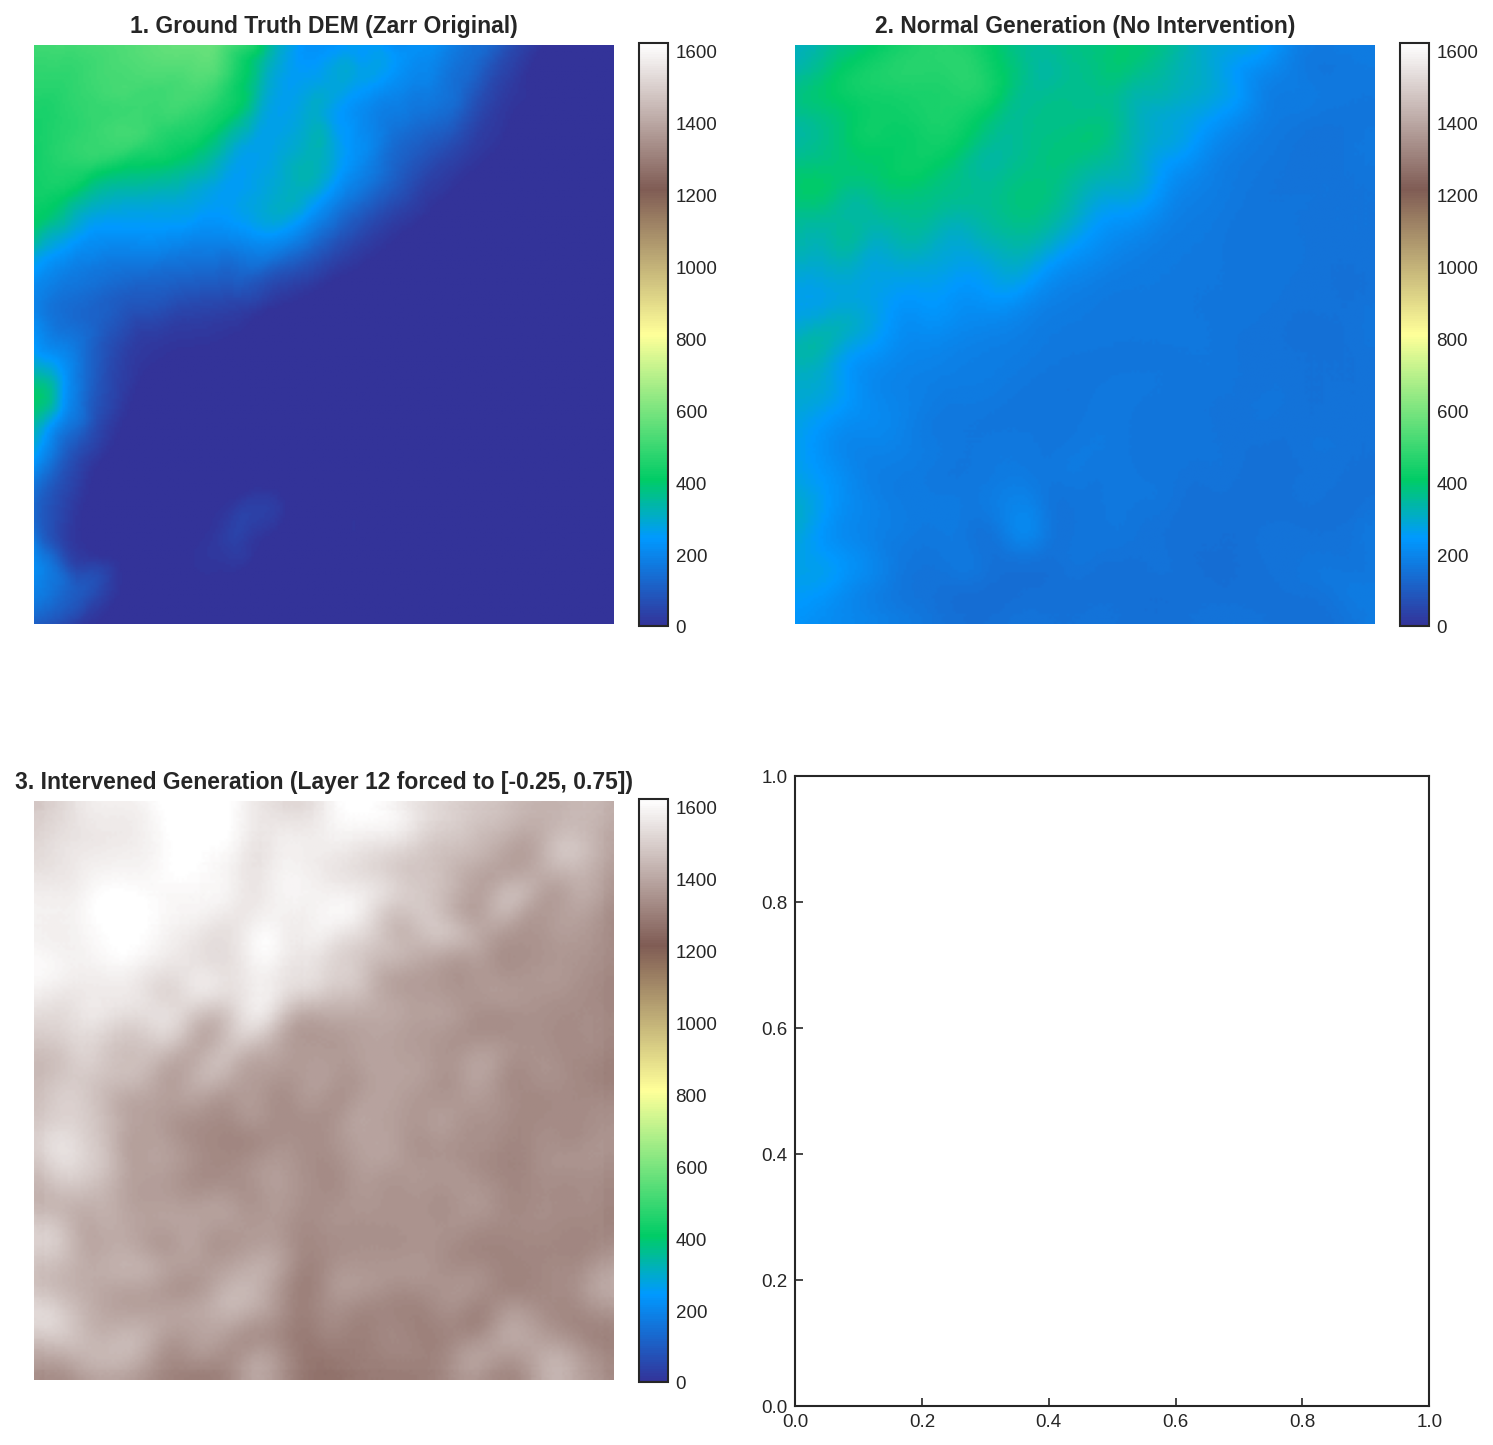

In [23]:
import tempfile
import math
import torch
import torch.nn.functional as F
import xarray as xr
from zarr.storage import ZipStore
import matplotlib.pyplot as plt

# ==========================================
# 1. ACCELERATED EXTRACTION FUNCTION
# ==========================================
class EncoderEarlyExit(Exception):
    """Custom exception to halt the model immediately after encoder extraction."""
    pass

def extract_terramind_latent(model, input_batch, indices):
    """
    Ultra-optimized feature extraction for testing. Short-circuits
    the model at the maximum requested layer while retaining full spatial states.
    """
    latents = []
    full_latents = []
    hook_handles = []
    captured_blocks = {}
    captured_norm = None

    max_requested_idx = max(indices)

    def make_capture_hook(layer_name, is_kill_gate=False):
        def hook_fn(module, layer_input, native_output):
            nonlocal captured_norm

            if isinstance(native_output, tuple):
                token_tensor = native_output[0].clone()
            elif isinstance(native_output, dict):
                token_tensor = native_output['x'].clone()
            else:
                token_tensor = native_output.clone()

            if layer_name == "encoder_norm":
                captured_norm = token_tensor
            else:
                captured_blocks[layer_name] = token_tensor

            if is_kill_gate:
                raise EncoderEarlyExit()
        return hook_fn

    for idx in indices:
        is_kill_gate = (idx == max_requested_idx)

        if idx == 0:
            target_layer = model.sampler.model.encoder_embeddings
            h = target_layer.register_forward_hook(make_capture_hook("block_0", is_kill_gate))
            hook_handles.append(h)
        elif idx == 12:
            target_layer = model.sampler.model.encoder_norm
            h = target_layer.register_forward_hook(make_capture_hook("encoder_norm", is_kill_gate))
            hook_handles.append(h)
        else:
            target_layer = model.sampler.model.encoder[idx - 1]
            h = target_layer.register_forward_hook(make_capture_hook(f"block_{idx}", is_kill_gate))
            hook_handles.append(h)

    if max_requested_idx != 12 and 12 not in indices:
        h_norm = model.sampler.model.encoder_norm.register_forward_hook(make_capture_hook("encoder_norm", is_kill_gate=True))
        hook_handles.append(h_norm)

    try:
        with torch.no_grad():
            _ = model(input_batch)
    except EncoderEarlyExit:
        pass
    finally:
        for handle in hook_handles:
            handle.remove()

    for idx in indices:
        if idx == 12 and captured_norm is not None:
            full_latents.append(captured_norm)
            latents.append(captured_norm.mean(dim=1).squeeze(0))
        elif f"block_{idx}" in captured_blocks:
            block_tensor = captured_blocks[f"block_{idx}"]
            full_latents.append(block_tensor)
            latents.append(block_tensor.mean(dim=1).squeeze(0))
        else:
            fallback_tensor = torch.zeros(192, device=input_batch.device)
            full_latents.append(fallback_tensor)
            latents.append(fallback_tensor)

    return latents, indices, full_latents


# ==========================================
# 2. ALIGNED WRAPPER FUNCTION
# ==========================================
def process_and_encode(sample, sample_dem, model, device, indices):
    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp:
        tmp.write(sample["zarr.zip"])
        tmp.flush()
        store = ZipStore(tmp.name, mode="r")
        ds = xr.open_zarr(store, consolidated=False)

    with tempfile.NamedTemporaryFile(suffix=".zip") as tmp_d:
        tmp_d.write(sample_dem["zarr.zip"])
        tmp_d.flush()
        store_dem = ZipStore(tmp_d.name, mode="r")
        ds_dem = xr.open_zarr(store_dem, consolidated=False)

    img_dem = ds_dem["bands"].isel(time=0).values.astype("float32")
    img_dem = torch.tensor(img_dem)

    mean_elev = img_dem.mean()
    std_elev = img_dem.std()
    range_elev = img_dem.max() - img_dem.min()
    img = ds["bands"].isel(time=0).values.astype("float32")
    img = torch.tensor(img)

    img = F.interpolate(img.unsqueeze(0), size=(224, 224), mode="bilinear")
    time_val = get_day_angle(str(ds["time"].isel(time=0).values))

    cloud = ds["cloud_mask"].isel(time=0).values
    cloud = torch.tensor(cloud).unsqueeze(0).float()
    cloud = F.interpolate(cloud.unsqueeze(0), size=(224, 224), mode="nearest")[0][0]
    cloud = cloud.mean()

    lat = float(ds["center_lat"].values)
    lon = float(ds["center_lon"].values)

    img = img.to(device)

    latents, indices, full_latents = extract_terramind_latent(model, img, indices)
    meta = [lat, lon, cloud, mean_elev, std_elev, range_elev, time_val]

    return latents, meta, full_latents, img


# ==========================================|
# 3. INTERVENTION HARNESS EXECUTION
# ==========================================
idx = 12  # Target encoder block to intervene upon
x_0 = -0.25  # Target value for the 1st most active dimension
y_0 = 0.75  # Target value for the 2nd most active dimension

# Regenerate dataset for this cell's execution
#dataset = generate_dataset(1)
#sample, sample_dem = next(iter(dataset))
latents, meta, full_latents, img = process_and_encode(sample, sample_dem, model, device, [idx])

# Pin manual seed for perfect baseline generation parity
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# --- PASS 1: Natural Generation ---
print("Running normal generation pipeline (No intervention)...")
with torch.no_grad():
    normal_outputs = model(img)
normal_dem = normal_outputs['DEM'].detach().cpu().squeeze().numpy()


# --- PASS 2: Geometric Subspace Intercepted Generation ---
def geometric_intervention_hook(module, layer_input, native_output):
    """
    Intercepts the layer hidden state, projects it into the subspace, forces the target active
    dimensions to (x_0, y_0), projects it back, and feeds it forward.
    """
    global x_old, y_old
    if isinstance(native_output, tuple):
        raw_tokens = native_output[0].clone()
    elif isinstance(native_output, dict):
        raw_tokens = native_output['x'].clone()
    else:
        raw_tokens = native_output.clone()

    orig_shape = raw_tokens.shape
    device = raw_tokens.device

    # Flatten dimensions across batch/sequence entries cleanly: [N, 192]
    X_flat = raw_tokens.view(-1, orig_shape[-1])

    with torch.no_grad():
        # 1. Forward Transform (Center and Rotate)
        X_centered = X_flat + t.to(device)
        X_rotated = torch.matmul(X_centered, R.to(device))

        # 2. Extract top active dimensions based on magnitude
        top_2_indices = torch.argsort(l.abs(), descending=True)[:2]

        # 3. Intervention Step: Overwrite target components
        x_old = X_rotated[:, top_2_indices[0]].mean().item()
        y_old = X_rotated[:, top_2_indices[1]].mean().item()
        X_rotated[:, top_2_indices[0]] = x_0
        X_rotated[:, top_2_indices[1]] = y_0

        # 4. Inverse Transform (Inverse Rotate via Transpose and Uncenter)
        X_back = torch.matmul(X_rotated, R.to(device).t())
        X_intervened = X_back - t.to(device)

    # Re-wrap hidden state to match native specifications
    modified_tokens = X_intervened.view(orig_shape)

    if isinstance(native_output, tuple):
        return (modified_tokens,) + native_output[1:]
    elif isinstance(native_output, dict):
        out_dict = native_output.copy()
        out_dict['x'] = modified_tokens
        return out_dict
    return modified_tokens


# Bind target layer
if idx == 12:
    target_layer = model.sampler.model.encoder_norm
elif idx == 0:
    target_layer = model.sampler.model.encoder_embeddings
else:
    target_layer = model.sampler.model.encoder[idx - 1]

# Register hook onto the active pipeline graph
hook_handle = target_layer.register_forward_hook(geometric_intervention_hook)

print(f"Running generation pipeline with INTERVENED latents at block_{idx}...")
try:
    with torch.no_grad():
        torch.manual_seed(42)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(42)
        hooked_outputs = model(img)
    hooked_dem = hooked_outputs['DEM'].detach().cpu().squeeze().numpy()
finally:
    hook_handle.remove()
    print("Intervention hook detached safely.")


# --- PASS 3: Ground Truth Zarr Extraction ---
with tempfile.NamedTemporaryFile(suffix=".zip") as tmp_dem:
    tmp_dem.write(sample_dem["zarr.zip"])
    tmp_dem.flush()
    store_dem = ZipStore(tmp_dem.name, mode="r")
    ds_dem = xr.open_zarr(store_dem, consolidated=False)
    ground_truth_dem = ds_dem["bands"].isel(time=0).values.astype("float32").squeeze()

import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F # Ensure F is imported here as well

# =========================
# Scientific plotting style
# =========================
plt.style.use('seaborn-v0_8-white')

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "figure.dpi": 150
})

me_deviation = ((hooked_dem - normal_dem)).mean()
print(f"Mean elevation deviation: {me_deviation}")
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# =========================
# Shared DEM normalization (IMPORTANT FIX)
# =========================
# Ensure ground_truth_dem is resized to match normal_dem and hooked_dem
# which are (224, 224) from the interpolation in process_and_encode
ground_truth_dem_tensor = torch.tensor(ground_truth_dem, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
ground_truth_dem_resized = F.interpolate(ground_truth_dem_tensor, size=(224, 224), mode='bilinear', align_corners=False).squeeze().numpy()

all_dem = np.stack([ground_truth_dem_resized, normal_dem, hooked_dem])
vmin, vmax = all_dem.min(), all_dem.max()

# =========================
# 1. Ground Truth
# =========================
im0 = axes[0, 0].imshow(ground_truth_dem_resized, cmap='terrain', vmin=vmin, vmax=vmax)
axes[0, 0].set_title('1. Ground Truth DEM (Zarr Original)', fontweight='bold')
axes[0, 0].axis('off')
fig.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

# =========================
# 2. Normal generation
# =========================
im1 = axes[0, 1].imshow(normal_dem, cmap='terrain', vmin=vmin, vmax=vmax)
axes[0, 1].set_title('2. Normal Generation (No Intervention)', fontweight='bold')
axes[0, 1].axis('off')
fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

# =========================
# 3. Intervention
# =========================
im2 = axes[1, 0].imshow(hooked_dem, cmap='terrain', vmin=vmin, vmax=vmax)
axes[1, 0].set_title(
    f'3. Intervened Generation (Layer {idx} forced to [{x_0}, {y_0}])',
    fontweight='bold'
)
axes[1, 0].axis('off')
fig.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

# =========================
# 4. Latent space projection
# =========================
dataset_path = "/content/latents_12_100000_for_intervention.pt"
saved_data = torch.load(dataset_path, map_location=device)

X = saved_data["latents"] # Shape: [N, 192]
y = saved_data["meta"][:, 3]

with torch.no_grad():
    X_centered = X.to(device) + t
    X_rotated = torch.matmul(X_centered, R)

    top_2_indices = torch.argsort(l.abs(), descending=True)[:2]
    active_dims = X_rotated[:, top_2_indices].cpu().numpy()

    scales = l[top_2_indices].cpu().numpy()
    print(f"Top 2 Lambda scales: {scales}")

ax = axes[1, 1]

sc = ax.scatter(
    active_dims[:, 0],
    active_dims[:, 1],
    c=y.cpu().numpy(),
    cmap='magma',
    s=5,
    alpha=0.4
)

ax.set_title('4. Latent Space ', fontweight='bold')
ax.grid(True, linewidth=0.4, alpha=0.3)

# Clean spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# =========================
# Arrow: (old -> new intervention point)
# =========================
ax.annotate(
    '',
    xy=(x_0, y_0),
    xytext=(x_old, y_old),
    arrowprops=dict(
        arrowstyle='->',
        lw=2.5,
        color='gray',
        alpha=0.9
    )
)

plt.tight_layout()
plt.show()

Running normal generation pipeline (No intervention)...
Running generation pipeline with INTERVENED latents at block_12...
Intervention hook detached safely.
Mean elevation deviation: -1413.439697265625
Top 2 Lambda scales: [7.2692986 6.9100027]


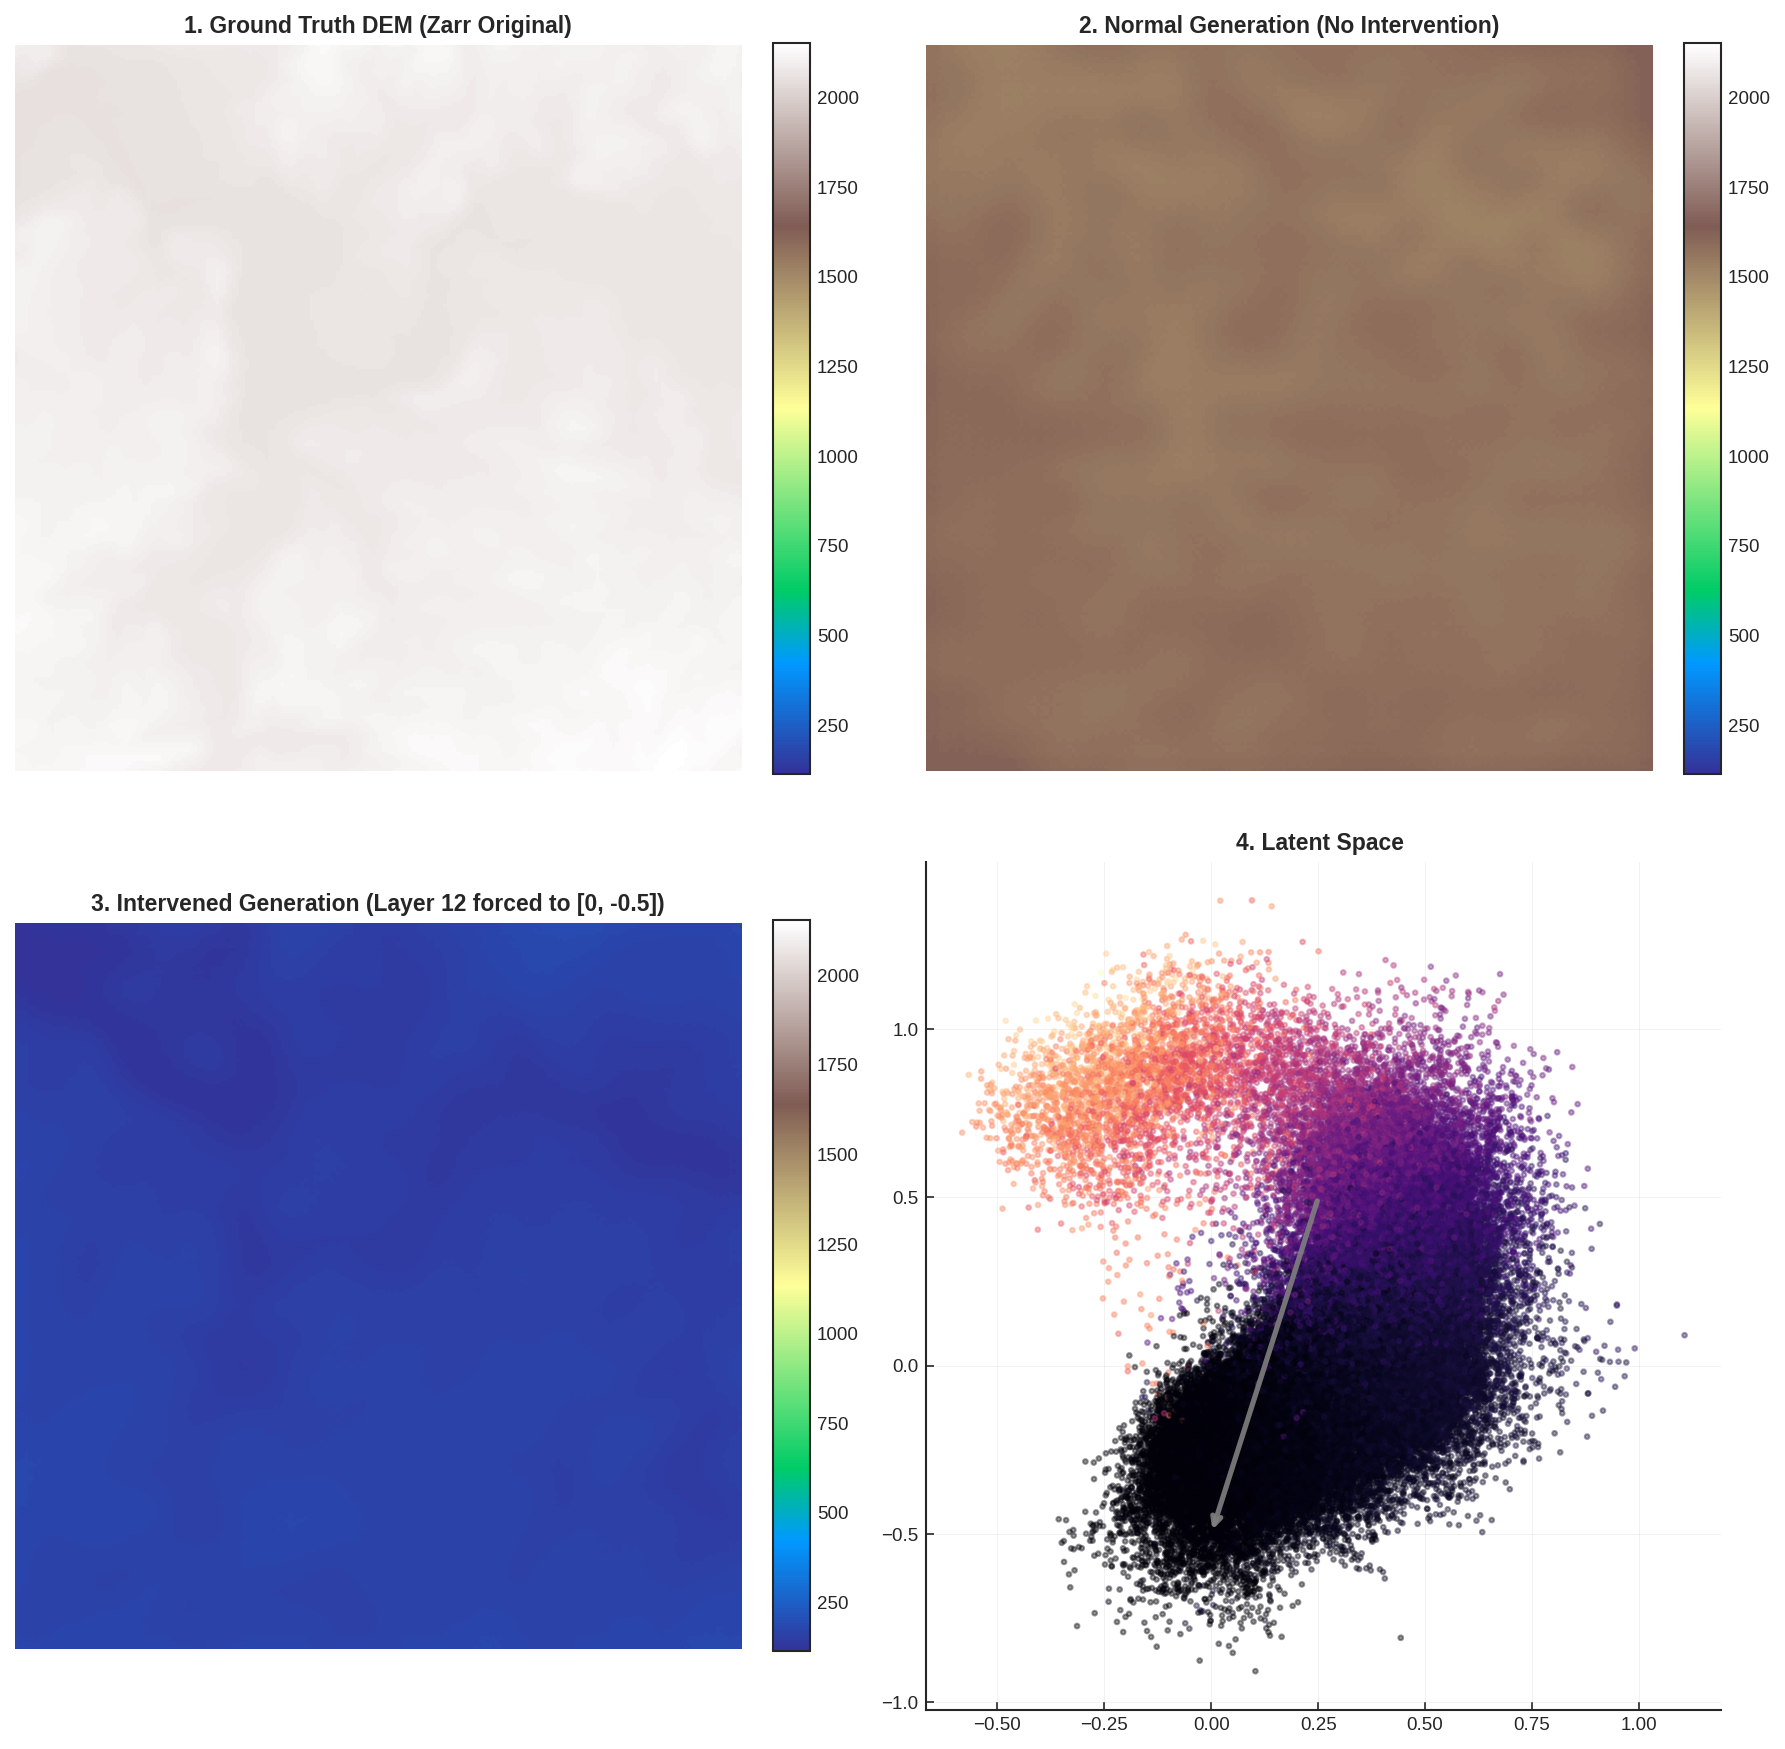

Running normal generation pipeline (No intervention)...
Running generation pipeline with INTERVENED latents at block_12...
Intervention hook detached safely.
Mean elevation deviation: -0.022235136479139328
Top 2 Lambda scales: [7.2692986 6.9100027]


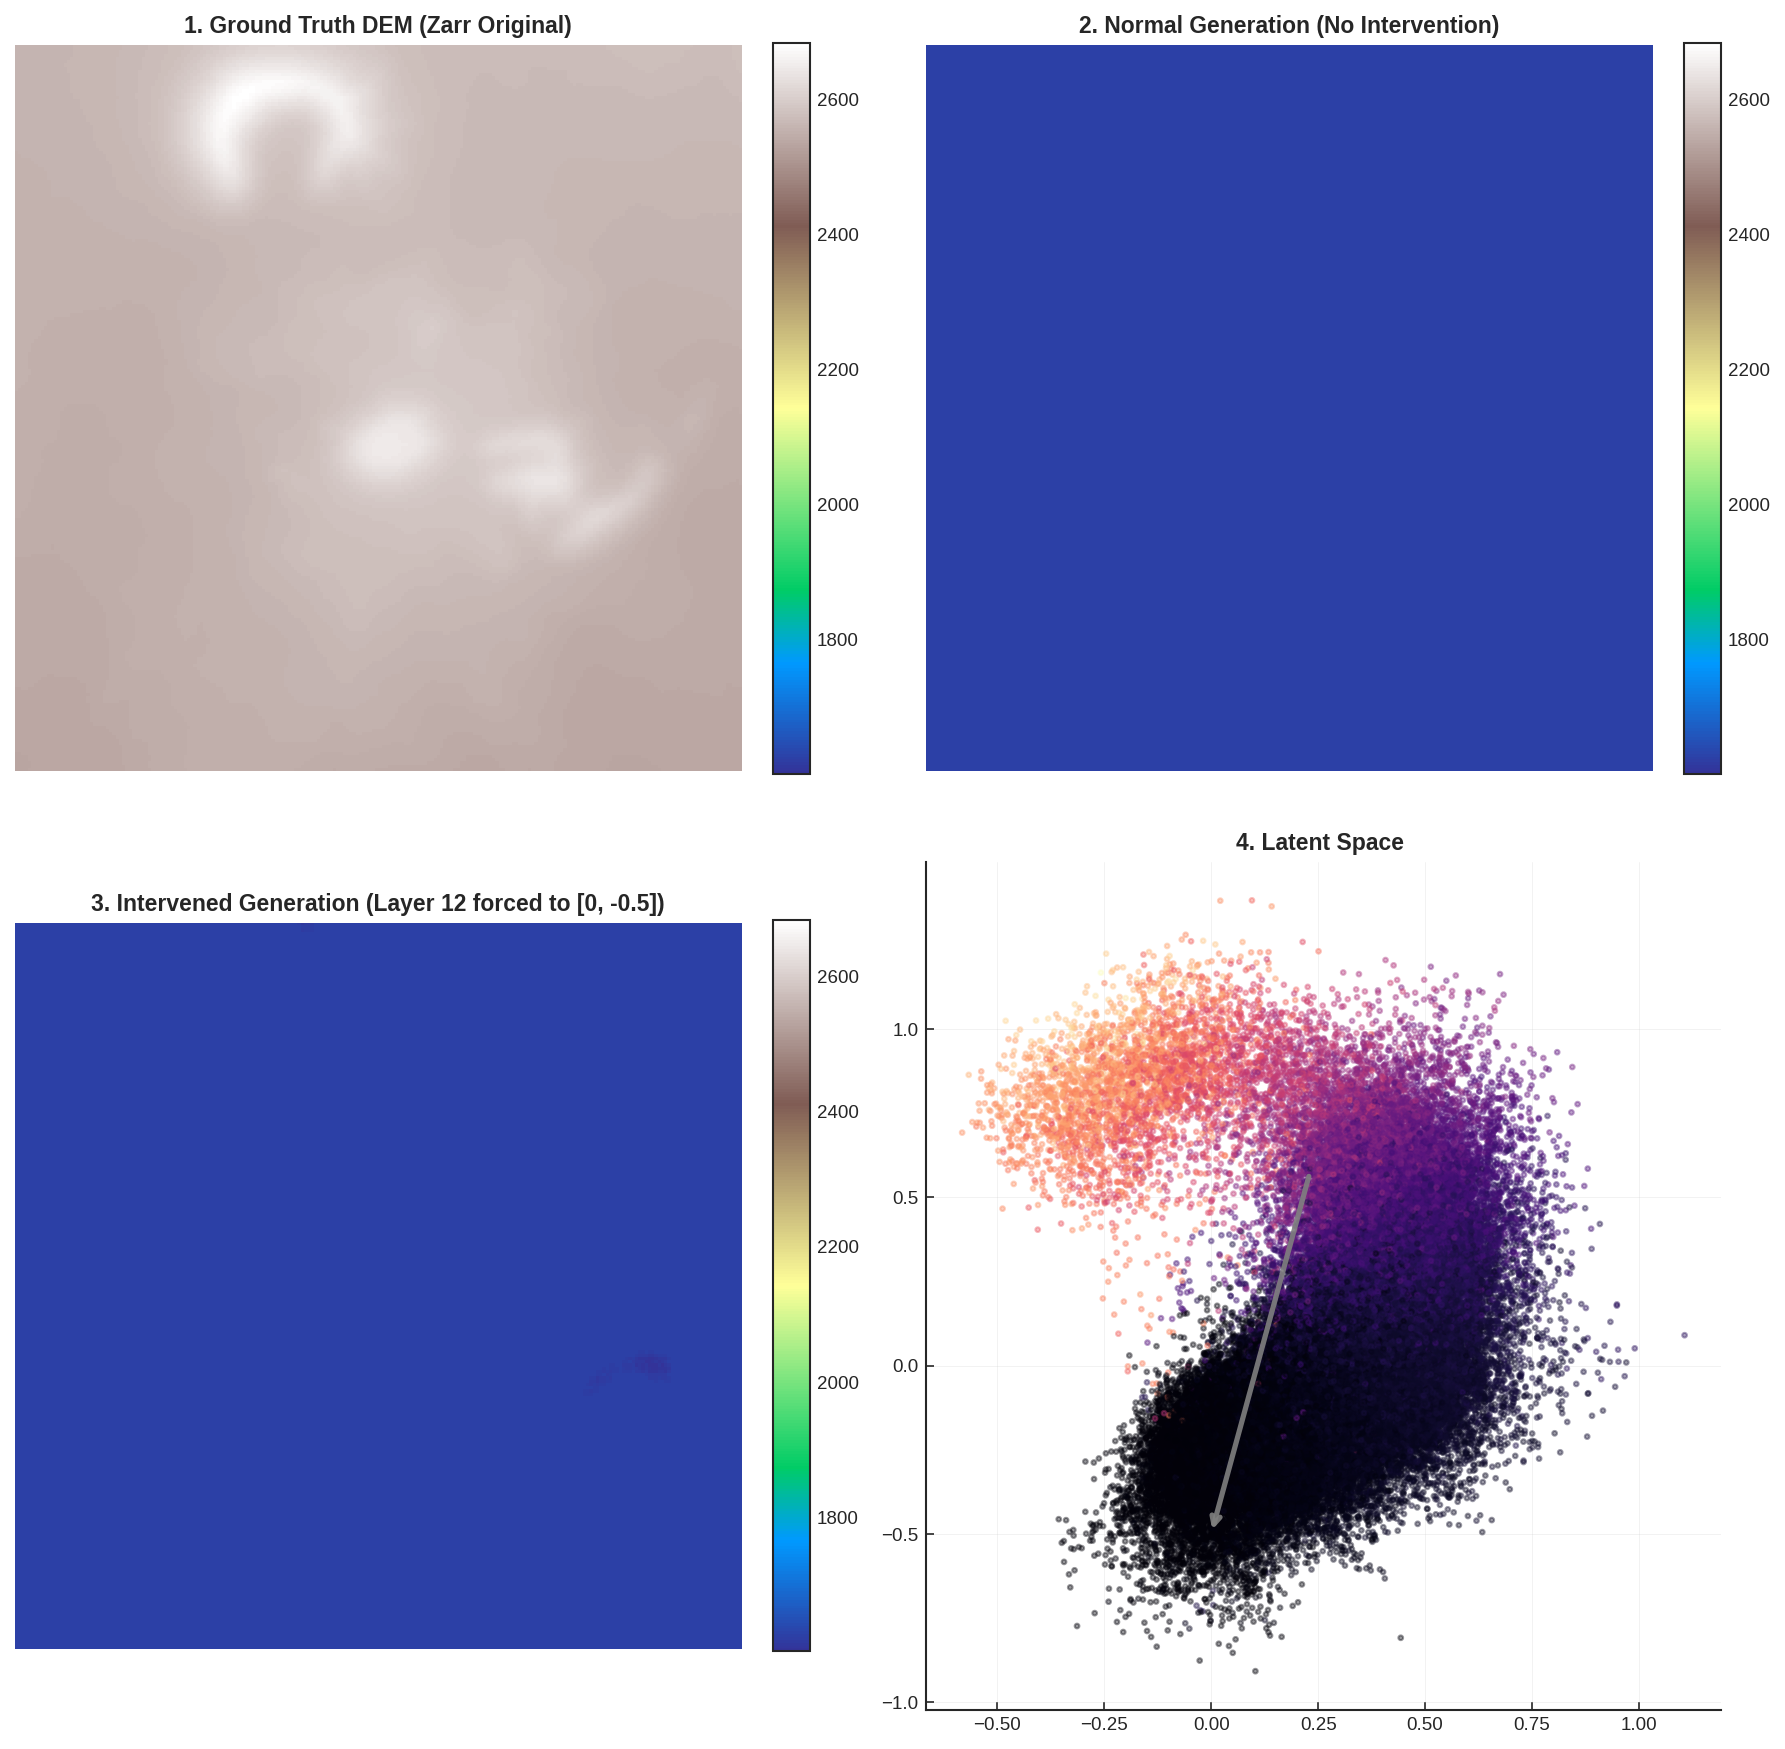

In [ ]:
X = data['latents']
y = data['meta'][:,3]
for i, duo in enumerate(potentials):
  sample, sample_dem = duo
  idx = 12  # Target encoder block to intervene upon
  x_0 = 0  # Target value for the 1st most active dimension
  y_0 = -0.5  # Target value for the 2nd most active dimension
  latents, meta, full_latents, img = process_and_encode(sample, sample_dem, model, device, [idx])

  # Pin manual seed for perfect baseline generation parity
  torch.manual_seed(42)
  if torch.cuda.is_available():
      torch.cuda.manual_seed_all(42)

  # --- PASS 1: Natural Generation ---
  print("Running normal generation pipeline (No intervention)...")
  with torch.no_grad():
      normal_outputs = model(img)
  normal_dem = normal_outputs['DEM'].detach().cpu().squeeze().numpy()


  # --- PASS 2: Geometric Subspace Intercepted Generation ---
  def geometric_intervention_hook(module, layer_input, native_output):
      """
      Intercepts the layer hidden state, projects it into the subspace, forces the target active
      dimensions to (x_0, y_0), projects it back, and feeds it forward.
      """
      global x_old, y_old
      if isinstance(native_output, tuple):
          raw_tokens = native_output[0].clone()
      elif isinstance(native_output, dict):
          raw_tokens = native_output['x'].clone()
      else:
          raw_tokens = native_output.clone()

      orig_shape = raw_tokens.shape
      device = raw_tokens.device

      # Flatten dimensions across batch/sequence entries cleanly: [N, 192]
      X_flat = raw_tokens.view(-1, orig_shape[-1])

      with torch.no_grad():
          # 1. Forward Transform (Center and Rotate)
          X_centered = X_flat + t.to(device)
          X_rotated = torch.matmul(X_centered, R.to(device))

          # 2. Extract top active dimensions based on magnitude
          top_2_indices = torch.argsort(l.abs(), descending=True)[:2]

          # 3. Intervention Step: Overwrite target components
          x_old = X_rotated[:, top_2_indices[0]].mean().item()
          y_old = X_rotated[:, top_2_indices[1]].mean().item()
          X_rotated[:, top_2_indices[0]] = x_0
          X_rotated[:, top_2_indices[1]] = y_0

          # 4. Inverse Transform (Inverse Rotate via Transpose and Uncenter)
          X_back = torch.matmul(X_rotated, R.to(device).t())
          X_intervened = X_back - t.to(device)

      # Re-wrap hidden state to match native specifications
      modified_tokens = X_intervened.view(orig_shape)

      if isinstance(native_output, tuple):
          return (modified_tokens,) + native_output[1:]
      elif isinstance(native_output, dict):
          out_dict = native_output.copy()
          out_dict['x'] = modified_tokens
          return out_dict
      return modified_tokens


  # Bind target layer
  if idx == 12:
      target_layer = model.sampler.model.encoder_norm
  elif idx == 0:
      target_layer = model.sampler.model.encoder_embeddings
  else:
      target_layer = model.sampler.model.encoder[idx - 1]

  # Register hook onto the active pipeline graph
  hook_handle = target_layer.register_forward_hook(geometric_intervention_hook)

  print(f"Running generation pipeline with INTERVENED latents at block_{idx}...")
  try:
      with torch.no_grad():
          torch.manual_seed(42)
          if torch.cuda.is_available():
              torch.cuda.manual_seed_all(42)
          hooked_outputs = model(img)
      hooked_dem = hooked_outputs['DEM'].detach().cpu().squeeze().numpy()
  finally:
      hook_handle.remove()
      print("Intervention hook detached safely.")


  # --- PASS 3: Ground Truth Zarr Extraction ---
  with tempfile.NamedTemporaryFile(suffix=".zip") as tmp_dem:
      tmp_dem.write(sample_dem["zarr.zip"])
      tmp_dem.flush()
      store_dem = ZipStore(tmp_dem.name, mode="r")
      ds_dem = xr.open_zarr(store_dem, consolidated=False)
      ground_truth_dem = ds_dem["bands"].isel(time=0).values.astype("float32").squeeze()

  # =========================
  # Scientific plotting style
  # =========================
  plt.style.use('seaborn-v0_8-white')

  plt.rcParams.update({
      "font.size": 10,
      "axes.titlesize": 11,
      "axes.labelsize": 10,
      "xtick.labelsize": 9,
      "ytick.labelsize": 9,
      "axes.linewidth": 1.0,
      "xtick.direction": "in",
      "ytick.direction": "in",
      "xtick.major.size": 4,
      "ytick.major.size": 4,
      "ytick.minor.size": 2,
      "figure.dpi": 150
  })

  me_deviation = ((hooked_dem - normal_dem)).mean()
  print(f"Mean elevation deviation: {me_deviation}")
  fig, axes = plt.subplots(2, 2, figsize=(12, 12))

  # =========================
  # Shared DEM normalization (IMPORTANT FIX)
  # =========================
  # Ensure ground_truth_dem is resized to match normal_dem and hooked_dem
  # which are (224, 224) from the interpolation in process_and_encode
  ground_truth_dem_tensor = torch.tensor(ground_truth_dem, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
  ground_truth_dem_resized = F.interpolate(ground_truth_dem_tensor, size=(224, 224), mode='bilinear', align_corners=False).squeeze().numpy()

  all_dem = np.stack([ground_truth_dem_resized, normal_dem, hooked_dem])
  vmin, vmax = all_dem.min(), all_dem.max()

  # =========================
  # 1. Ground Truth
  # =========================
  im0 = axes[0, 0].imshow(ground_truth_dem_resized, cmap='terrain', vmin=vmin, vmax=vmax)
  axes[0, 0].set_title('1. Ground Truth DEM (Zarr Original)', fontweight='bold')
  axes[0, 0].axis('off')
  fig.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

  # =========================
  # 2. Normal generation
  # =========================
  im1 = axes[0, 1].imshow(normal_dem, cmap='terrain', vmin=vmin, vmax=vmax)
  axes[0, 1].set_title('2. Normal Generation (No Intervention)', fontweight='bold')
  axes[0, 1].axis('off')
  fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

  # =========================
  # 3. Intervention
  # =========================
  im2 = axes[1, 0].imshow(hooked_dem, cmap='terrain', vmin=vmin, vmax=vmax)
  axes[1, 0].set_title(
      f'3. Intervened Generation (Layer {idx} forced to [{x_0}, {y_0}])',
      fontweight='bold'
  )
  axes[1, 0].axis('off')
  fig.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

  # =========================
  # 4. Latent space projection
  # =========================
  with torch.no_grad():
      X_centered = X.to(device) + t
      X_rotated = torch.matmul(X_centered, R)

      top_2_indices = torch.argsort(l.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = l[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  ax = axes[1, 1]

  sc = ax.scatter(
      active_dims[:, 0],
      active_dims[:, 1],
      c=y.cpu().numpy(),
      cmap='magma',
      s=5,
      alpha=0.4
  )

  ax.set_title('4. Latent Space ', fontweight='bold')
  ax.grid(True, linewidth=0.4, alpha=0.3)

  # Clean spines
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  # =========================
  # Arrow: (old -> new intervention point)
  # =========================
  ax.annotate(
      '',
      xy=(x_0, y_0),
      xytext=(x_old, y_old),
      arrowprops=dict(
          arrowstyle='->',
          lw=2.5,
          color='gray',
          alpha=0.9
      )
  )

  plt.tight_layout()
  plt.show()

In [ ]:
indices = [i for i, x in enumerate(me_boyz) if i not in [187, 188, 189, 190, 191]]

print(indices)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186]


In [ ]:
import sys
import numpy as np
from tqdm.notebook import tqdm

# Force NumPy to report a version Numba is happy with
np.__version__ = "2.0.0"

# Now import shap (it will read the faked version and initialize successfully)
import shap

print("SHAP imported successfully!")

# --- Define your superfeature mapping ---
# Group your 192 latent indices into a few logical groups (e.g., 10 superfeatures)
# 1. Initialize your special first superfeature
superfeatures_dict = {0: [0, 1]}

# 2. Dynamically chunk the remaining 190 indices into groups of 5
remaining_indices = list(range(2, 192))
chunk_size = 5
#medians for baseline
X_median_raw = torch.median(X, dim=0).values  # Shape: (192,)
X_median_tensor = X_median_raw.to(device, dtype=torch.float32)
with torch.no_grad():
    X_median_centered = X_median_tensor + t.to(device)
    X_median_rotated = torch.matmul(X_median_centered, R.to(device))

for i in range(38):
    start_idx = i * chunk_size
    end_idx = start_idx + chunk_size

    # Key mapping from 1 to 38
    superfeatures_dict[i + 1] = remaining_indices[start_idx:end_idx]

# Quick validation check
print(f"Total superfeatures generated: {len(superfeatures_dict)}")
print(f"Superfeature 1 handles: {superfeatures_dict[1]}")
print(f"Superfeature 38 handles: {superfeatures_dict[38]}")
NUM_SUPERFEATURES = len(superfeatures_dict)

def shap_predict_wrapper(coalition_matrix):
    """
    coalition_matrix: numpy array of shape (batch_size, NUM_SUPERFEATURES)
                      Contains 1s (keep feature) and 0s (intervene/zero out).
    """
    predictions = []

    # Process one sample/coalition combination at a time
    # (Since hooks modify global layer behavior per forward pass)
    for coalition in tqdm(coalition_matrix, desc="SHAP Evaluations", leave=False):
        # Determine exactly WHICH raw latent indices need to be wiped out (where coalition == 0)
        indices_to_wipe = []
        for sf_idx, status in enumerate(coalition):
            if status == 0: # If the superfeature is 'turned off' in this game theory subset
                indices_to_wipe.extend(superfeatures_dict[sf_idx])

        # --- Your Custom Hook Logic ---
        def geometric_intervention_hook(module, layer_input, native_output):
            if isinstance(native_output, tuple):
                raw_tokens = native_output[0].clone()
            elif isinstance(native_output, dict):
                raw_tokens = native_output['x'].clone()
            else:
                raw_tokens = native_output.clone()

            orig_shape = raw_tokens.shape
            device = raw_tokens.device
            X_flat = raw_tokens.view(-1, orig_shape[-1])

            with torch.no_grad():
                X_centered = X_flat + t.to(device)
                X_rotated = torch.matmul(X_centered, R.to(device))

                # Get the sorted latent features
                feature_indices = torch.argsort(l.abs(), descending=True)

                # Zero out only the indices belonging to the "disabled" superfeatures
                if len(indices_to_wipe) > 0:
                    target_indices = feature_indices[indices_to_wipe]
                    X_rotated[:, target_indices] = X_median_rotated[target_indices]

                X_back = torch.matmul(X_rotated, R.to(device).t())
                X_intervened = X_back - t.to(device)

            modified_tokens = X_intervened.view(orig_shape)

            if isinstance(native_output, tuple):
                return (modified_tokens,) + native_output[1:]
            elif isinstance(native_output, dict):
                out_dict = native_output.copy()
                out_dict['x'] = modified_tokens
                return out_dict
            return modified_tokens

        # Register hook, run model, pull target metric, remove hook
        hook_handle = target_layer.register_forward_hook(geometric_intervention_hook)
        try:
            with torch.no_grad():
                hooked_outputs = model(img) # assuming 'img' and 'model' are in scope
            hooked_dem = hooked_outputs['DEM'].detach().cpu().squeeze().numpy()
            predictions.append(hooked_dem.mean())
        finally:
            hook_handle.remove()

    return np.array(predictions)

SHAP imported successfully!
Total superfeatures generated: 39
Superfeature 1 handles: [2, 3, 4, 5, 6]
Superfeature 38 handles: [187, 188, 189, 190, 191]


SHAP Evaluations:   0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

SHAP Evaluations:   0%|          | 0/1 [00:00<?, ?it/s]

SHAP Evaluations:   0%|          | 0/1500 [00:00<?, ?it/s]

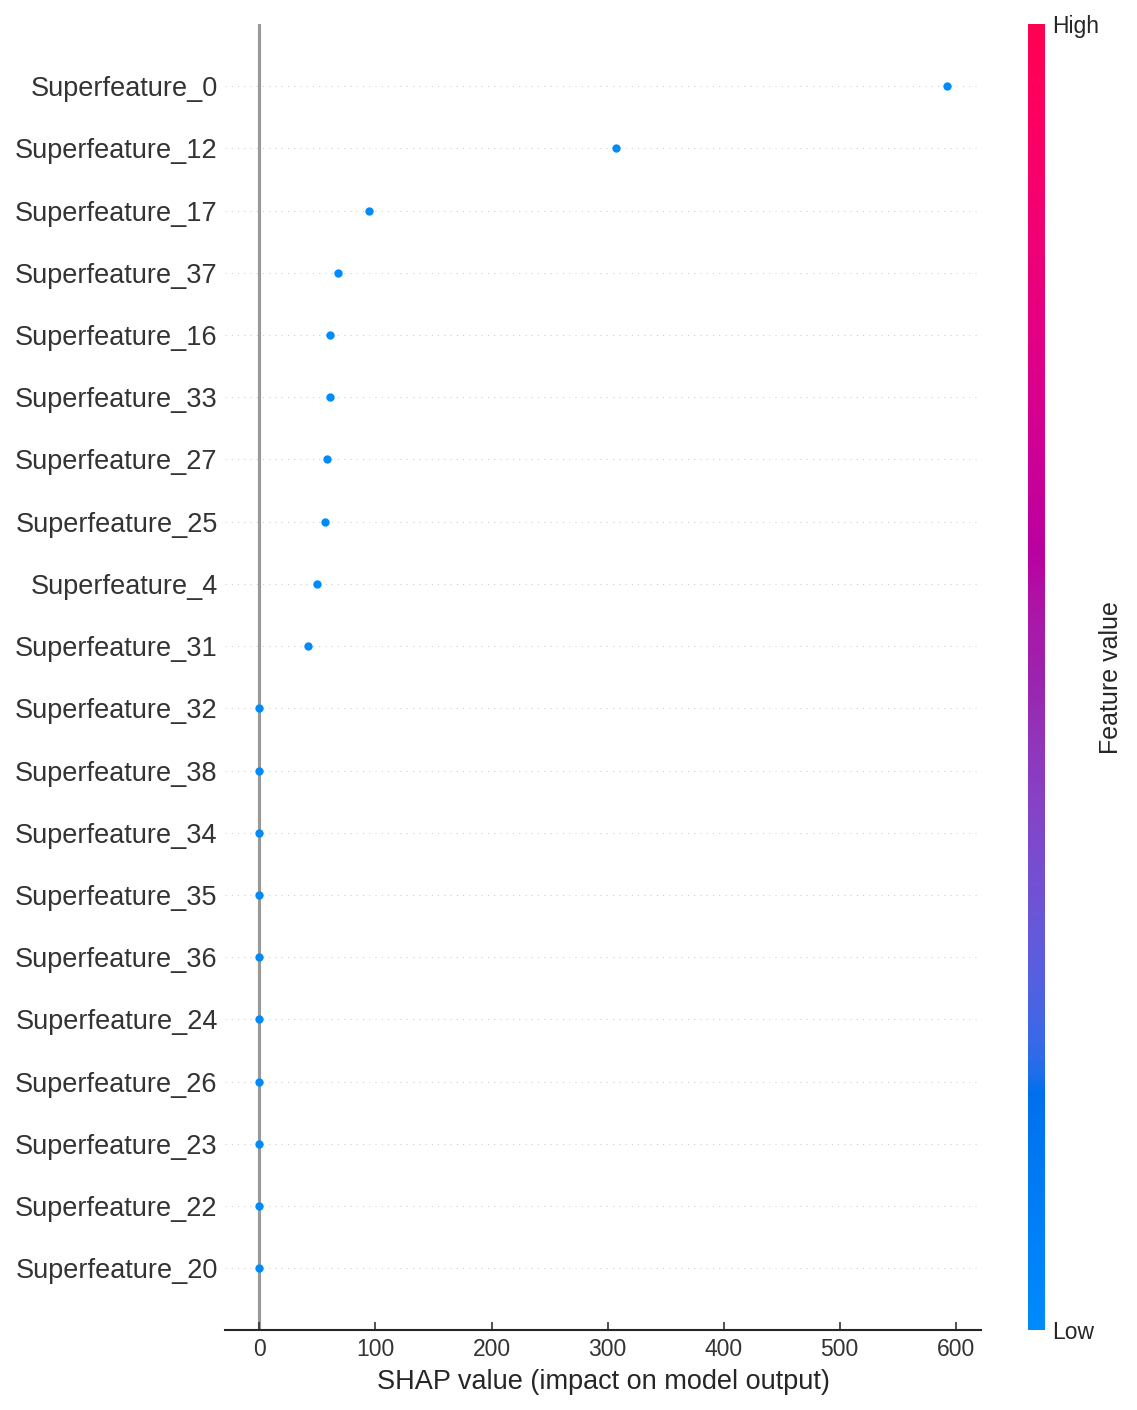

[[592.15401936   0.           0.           0.          49.52052183
    0.           0.           0.           0.           0.
    0.           0.         307.11249068   0.           0.
    0.          61.22052925  94.63950433   0.           0.
    0.           0.           0.           0.           0.
   56.31112619   0.          58.4907285    0.           0.
    0.          41.86154489   0.          60.83054511   0.
    0.           0.          67.80411926   0.        ]]


In [ ]:
sample, sample_dem = potentials[0]
background_state = np.zeros((1, NUM_SUPERFEATURES))
explainer = shap.KernelExplainer(shap_predict_wrapper, background_state)
test_instance = np.ones((1, NUM_SUPERFEATURES))
shap_values = explainer.shap_values(test_instance, nsamples=1500)
feature_names = [f"Superfeature_{i}" for i in range(NUM_SUPERFEATURES)]
shap.summary_plot(shap_values, test_instance, feature_names=feature_names)
print(shap_values)

In [ ]:
shap_values = shap_values[0]

<>:91: SyntaxWarning: invalid escape sequence '\s'
<>:91: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2777/2170768624.py:91: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel("Cumulative SHAP Value Impact ($\sum \phi_i$)", fontsize=9.5, labelpad=8)
/usr/local/lib/python3.12/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.12/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitesp

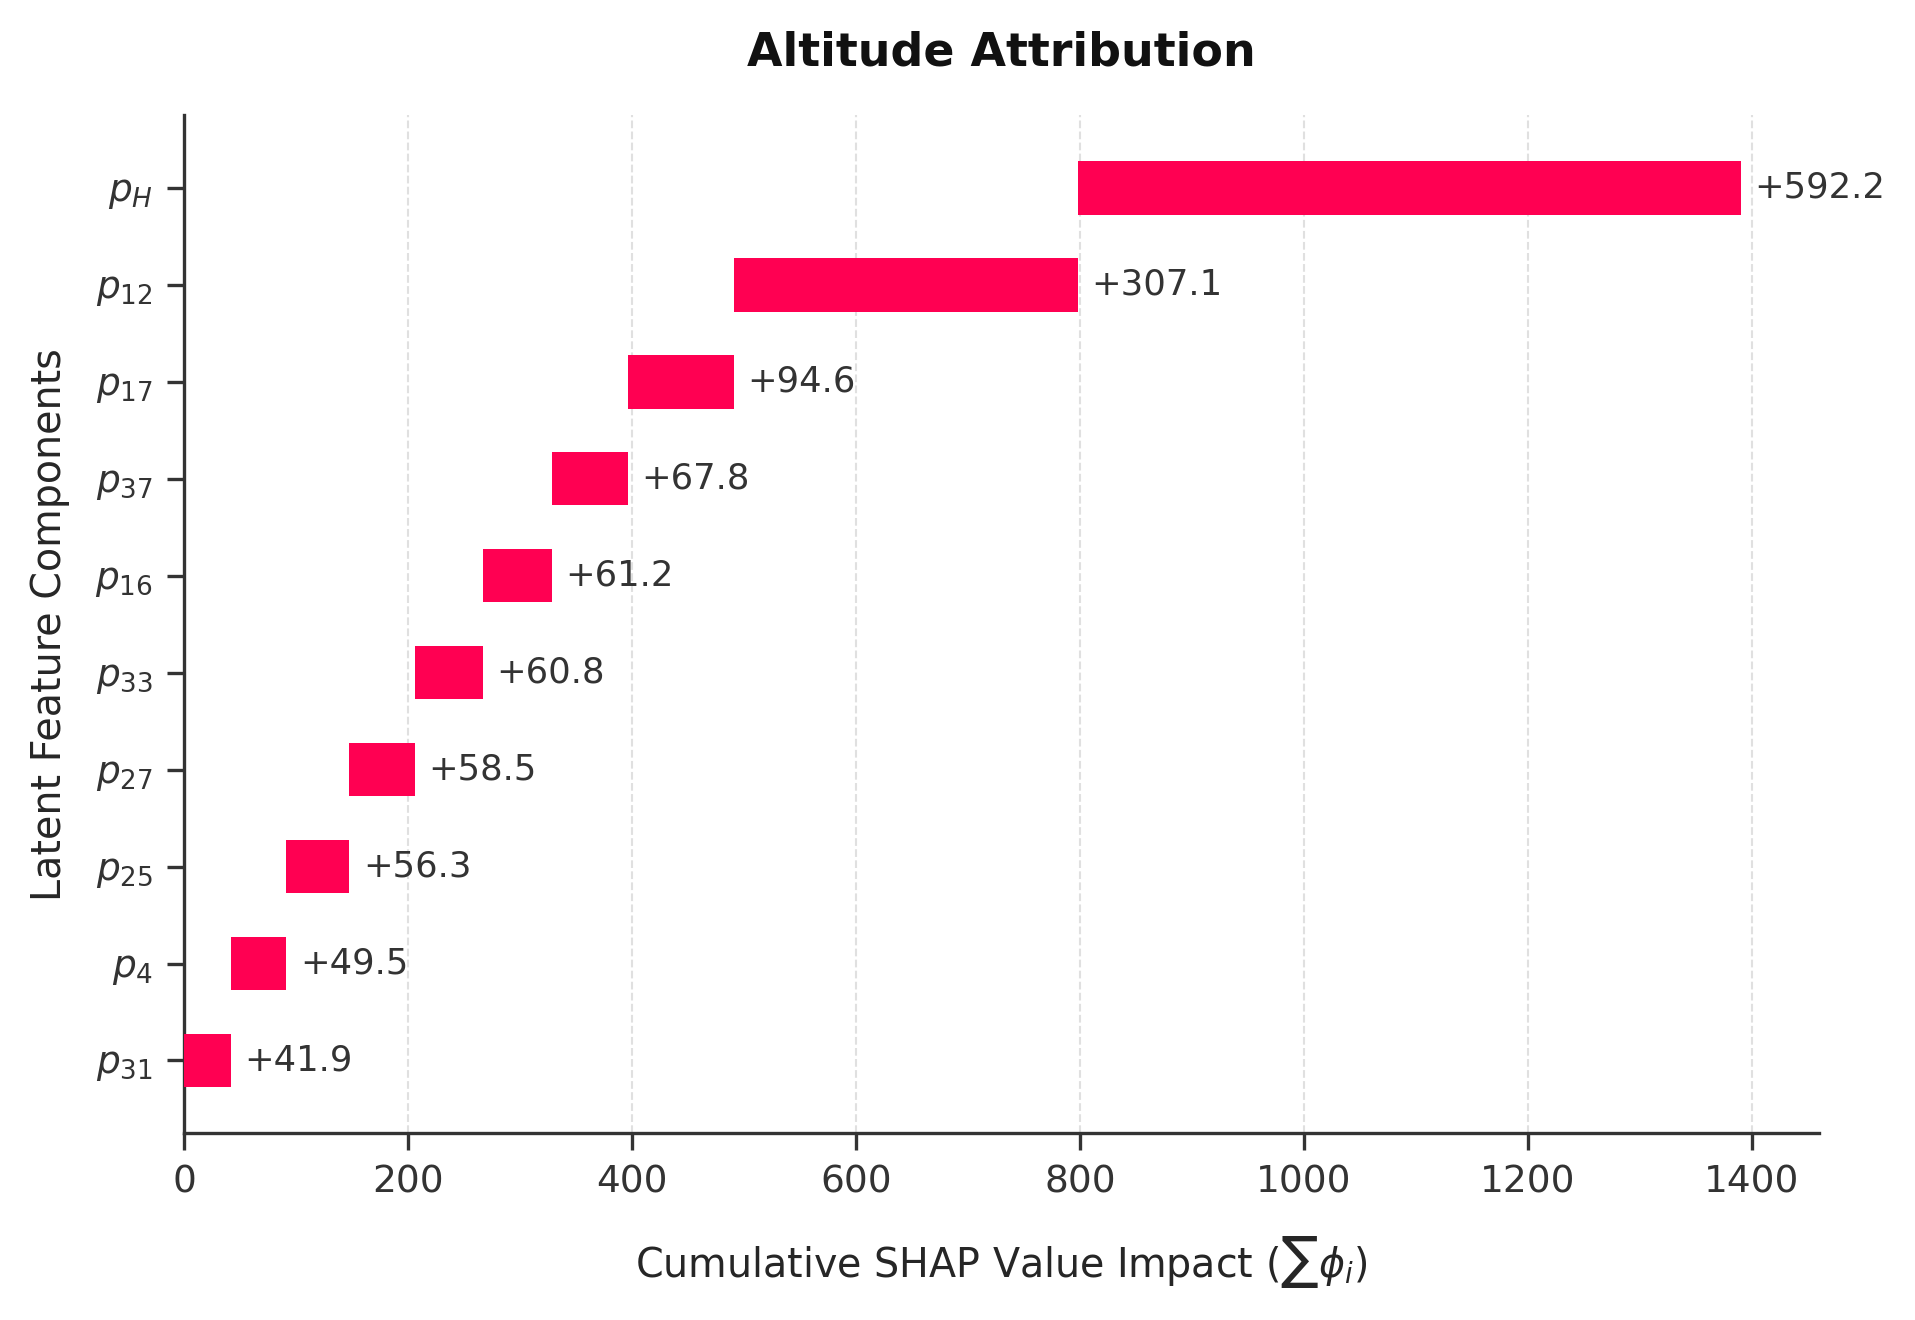

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set global scientific plotting parameters
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False  # Correctly render hyphen/minus sign

feature_names = [f"p_{i}" for i in range(len(shap_values))]
feature_names[0] = f"p_H"
# 2. Data Processing & Filtering
df = pd.DataFrame({"Feature": feature_names, "Shapley Value": shap_values})
df = df[df["Shapley Value"] != 0.0].copy()

# Sort ascending by absolute value so largest impacts plot at the top in barh
df["Abs_Value"] = df["Shapley Value"].abs()
df = df.sort_values(by="Abs_Value", ascending=True).drop(columns=["Abs_Value"])

# Convert feature names to formal math notation style for the journal look
df["Feature_Math"] = df["Feature"].apply(
    lambda x: f"$p_{{{x.split('_')[1]}}}$"
)

# Calculate sequential waterfall steps
df["Cumulative"] = df["Shapley Value"].cumsum()
df["Base"] = df["Cumulative"].shift(1).fillna(0)

# 3. Initialize High-Resolution Figure
fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=300)

# Color palette: Professional SHAP crimson for positive contributions
colors = ["#ff0052" if x >= 0 else "#008bfb" for x in df["Shapley Value"]]

# 4. Plot Horizontal Waterfall Bars
bars = ax.barh(
    df["Feature_Math"],
    df["Shapley Value"],
    left=df["Base"],
    color=colors,
    edgecolor="none",  # Clean, modern borderless bars
    height=0.55,
    zorder=3,  # Ensure bars sit on top of gridlines
)

# 5. Fine-Tune Scientific Grids and Spines
ax.xaxis.grid(
    True, linestyle="--", linewidth=0.5, color="#e0e0e0", zorder=0
)  # Subtle X grid
ax.yaxis.grid(False)  # Remove vertical grid lines

# Retain only structural axes (Left and Bottom)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)
ax.spines["left"].set_color("#333333")
ax.spines["bottom"].set_color("#333333")

# Ensure tick marks point outwards professionally
ax.tick_params(
    axis="both", direction="out", labelsize=9, colors="#333333", width=0.8
)

# 6. Precise Text Annotations
for bar in bars:
    width = bar.get_width()
    base = bar.get_x()
    endpoint = base + width

    # Place label slightly to the right of the progressive step completion
    ax.text(
        endpoint + 12,
        bar.get_y() + bar.get_height() / 2,
        f"+{width:.1f}",
        va="center",
        ha="left",
        fontsize=8.5,
        color="#333333",
        fontweight="regular",
    )

# 7. Labels & Layout Settings
plt.title(
    "Altitude Attribution",
    fontsize=11,
    fontweight="bold",
    pad=12,
    color="#111111",
)
plt.xlabel("Cumulative SHAP Value Impact ($\sum \phi_i$)", fontsize=9.5, labelpad=8)
plt.ylabel("Latent Feature Components", fontsize=9.5, labelpad=6)

# Dynamically pad the right side of the plot so text annotations don't cut off
plt.xlim(0, df["Cumulative"].max() + 70)
plt.tight_layout()

# Display plot
plt.show()

In [ ]:
from huggingface_hub import hf_hub_download

# --- 1. Authenticate (Only if the dataset is gated) ---
# You can run `huggingface-cli login` in your terminal or use:
# from huggingface_hub import login; login("your_token")
def generate_dataset(id):
  print()
  print('Loading:')
  REPO_ID = "ibm-esa-geospatial/TerraMesh"
  SHARD = f"majortom_shard_00000{id}.tar"
  print(SHARD)

  # --- 2. Download shards to local cache ---
  # This returns the local file path on your machine
  local_s2 = hf_hub_download(repo_id=REPO_ID, filename=f"train/S2L2A/{SHARD}", repo_type="dataset")
  local_dem = hf_hub_download(repo_id=REPO_ID, filename=f"train/DEM/{SHARD}", repo_type="dataset")

  # --- 3. Initialize WebDataset from local files ---
  ds_s2 = wds.WebDataset(local_s2, shardshuffle=False).decode()
  ds_dem = wds.WebDataset(local_dem, shardshuffle=False).decode()
  # Join streams
  return zip(ds_s2, ds_dem)

def get_day_angle(timestamp_str):
    """
    Converts a timestamp string to an angle in radians.
    0 -> January 1st
    pi -> Middle of the year
    2pi -> End of the year
    """
    # 1. Parse the date (ignoring nanoseconds beyond microseconds)
    dt = datetime.fromisoformat(timestamp_str.split('.')[0])

    # 2. Get the day of the year (1 to 365 or 366)
    day_of_year = dt.timetuple().tm_yday

    # 3. Determine the total days in that specific year (leap year check)
    year = dt.year
    is_leap = (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0)
    total_days = 366 if is_leap else 365

    # 4. Calculate the angle
    # We subtract 1 from day_of_year so that Jan 1st (Day 1) starts at exactly 0.0
    angle = ((day_of_year - 1) / total_days) * (2 * math.pi)

    return angle